# 13 · Sensibilidad a los parámetros cinéticos

Modificaremos un parámetro del modelo a la vez para estudiar cómo cambia la velocidad observada. Este es un análisis de sensibilidad del prototipo, no una estimación de parámetros reales.

> **ProteinMotorSim 0.1.1** · Ejemplo educativo. Las tasas predeterminadas del modelo son ilustrativas y no representan todavía una parametrización experimental validada.

## Preparación del entorno

Esta celda localiza automáticamente la raíz del repositorio e incorpora `src/` a la ruta de importación. Instala antes las dependencias con `python -m pip install -e ".[dev,viz]"` y selecciona el kernel `Python (ProteinMotorSim)`.

In [5]:
from pathlib import Path
import sys

# Busca la raíz del proyecto desde el directorio actual o sus carpetas padre.
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in _candidates if (path / "pyproject.toml").exists() and (path / "src").is_dir()),
    None,
)

if PROJECT_ROOT is None:
    raise RuntimeError(
        "No se encontró ProteinMotorSim. Abre JupyterLab desde la carpeta raíz "
        "del proyecto o desde su carpeta notebooks/."
    )

sys.path.insert(0, str(PROJECT_ROOT / "src"))
print(f"Proyecto detectado: {PROJECT_ROOT}")

Proyecto detectado: /home/zix/ProteinMotorSim


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import replace

from protein_motor_sim import Environment, GillespieSimulator, Kinesin1
from protein_motor_sim.models.kinesin.parameters import KinesinParameters
from protein_motor_sim.simulation.ensemble import run_ensemble
from protein_motor_sim.analysis.statistics import summarize_trajectories

base_parameters = KinesinParameters()
environment = Environment(atp_concentration=1.0e-3, temperature_K=310.0)
simulator = GillespieSimulator()
forward_rates = np.array([40.0, 60.0, 80.0, 100.0, 140.0, 180.0])
means, stds = [], []

## 1. Variar la tasa de avance sin carga

In [7]:
for index, rate in enumerate(forward_rates):
    parameters = replace(base_parameters, forward_step_rate_s=float(rate))
    motor = Kinesin1(parameters=parameters)
    ensemble = run_ensemble(
        simulator, motor, environment,
        t_max=0.4, n_runs=25, seed=500 + index,
    )
    stats = summarize_trajectories(ensemble.trajectories)
    means.append(stats.mean_velocity_nm_s)
    stds.append(stats.std_velocity_nm_s)
    print(f"k_forward={rate:6.1f} s^-1 | v={stats.mean_velocity_nm_s:8.2f} ± {stats.std_velocity_nm_s:7.2f} nm/s")

k_forward=  40.0 s^-1 | v=  188.47 ±   44.79 nm/s
k_forward=  60.0 s^-1 | v=  282.90 ±   59.77 nm/s
k_forward=  80.0 s^-1 | v=  342.29 ±   55.48 nm/s
k_forward= 100.0 s^-1 | v=  337.02 ±   80.73 nm/s
k_forward= 140.0 s^-1 | v=  388.17 ±   64.23 nm/s
k_forward= 180.0 s^-1 | v=  441.68 ±   79.45 nm/s


## 2. Graficar sensibilidad

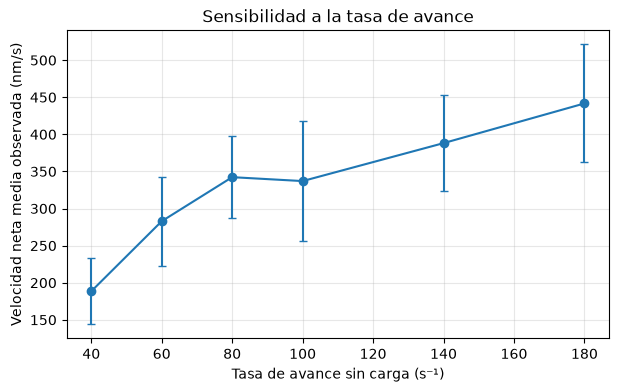

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(forward_rates, means, yerr=stds, marker="o", capsize=3)
ax.set_xlabel("Tasa de avance sin carga (s⁻¹)")
ax.set_ylabel("Velocidad neta media observada (nm/s)")
ax.set_title("Sensibilidad a la tasa de avance")
ax.grid(alpha=0.3)
plt.show()

## 3. Preguntas para explorar

- ¿La velocidad aumenta linealmente con la tasa de avance?
- ¿Qué otros pasos limitan el ciclo cuando se aumenta mucho la tasa de avance?
- ¿Cómo cambiaría el resultado si variamos simultáneamente la hidrólisis o la asociación de ATP?

Estas preguntas ayudan a identificar qué parte del ciclo controla la velocidad global.